# Heart Disease Prediction — Exploratory Data Analysis

## Objective

This notebook performs exploratory data analysis (EDA) on the UCI Heart Disease dataset. The analysis examines the dataset structure, data quality, missing values, feature distributions, relationships between variables, and target class distribution before model development.

The raw dataset is acquired using the reproducible data acquisition script in `src/download_data.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 1. Load the Dataset

The raw dataset generated by the data acquisition step is loaded for exploration.

In [2]:
DATA_PATH = Path("../data/raw/heart_disease.csv")

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 2. Dataset Structure and Data Quality

Before performing visual analysis or preprocessing, the dataset is inspected for data types, missing values, duplicate records, and the distribution of the target variable.

In [4]:
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\nTarget distribution:")
print(df["num"].value_counts().sort_index())

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object

Missing values:
ca      4
thal    2
dtype: int64

Duplicate rows: 0

Target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


## 3. Target Preparation

The original UCI target (`num`) represents heart disease diagnosis using values from 0 to 4. For this assignment, the problem is formulated as binary classification:

- **0** — No heart disease
- **1** — Heart disease present

Therefore, an original `num` value of 0 is retained as class 0, while values greater than 0 are mapped to class 1.

In [5]:
df["target"] = (df["num"] > 0).astype(int)

print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

print("\nBinary target percentages:")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(2))

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Binary target percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


## 4. Target Class Distribution

The binary target contains 164 patients without heart disease and 139 patients with heart disease. The classes are relatively balanced, reducing the risk of strong class-imbalance bias during model training.

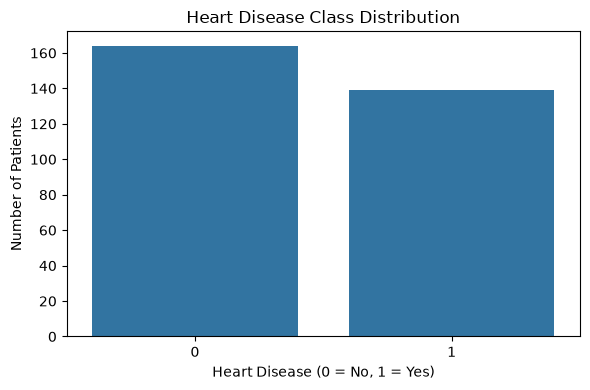

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target")

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

## 5. Missing Value Handling

Missing values were identified in the `ca` and `thal` features. Since only a small number of values are missing, they are imputed using the median of their respective columns rather than removing observations.

The raw dataset remains unchanged; preprocessing is performed on a separate copy of the data.

In [7]:
df_clean = df.copy()

for column in ["ca", "thal"]:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

print("Missing values after imputation:")
print(df_clean.isnull().sum().sum())

Missing values after imputation:
0


## 6. Feature Distributions

Histograms are used to examine the distributions of the continuous numerical features. This helps identify differences in scale, skewness, and potential unusual values before model development.

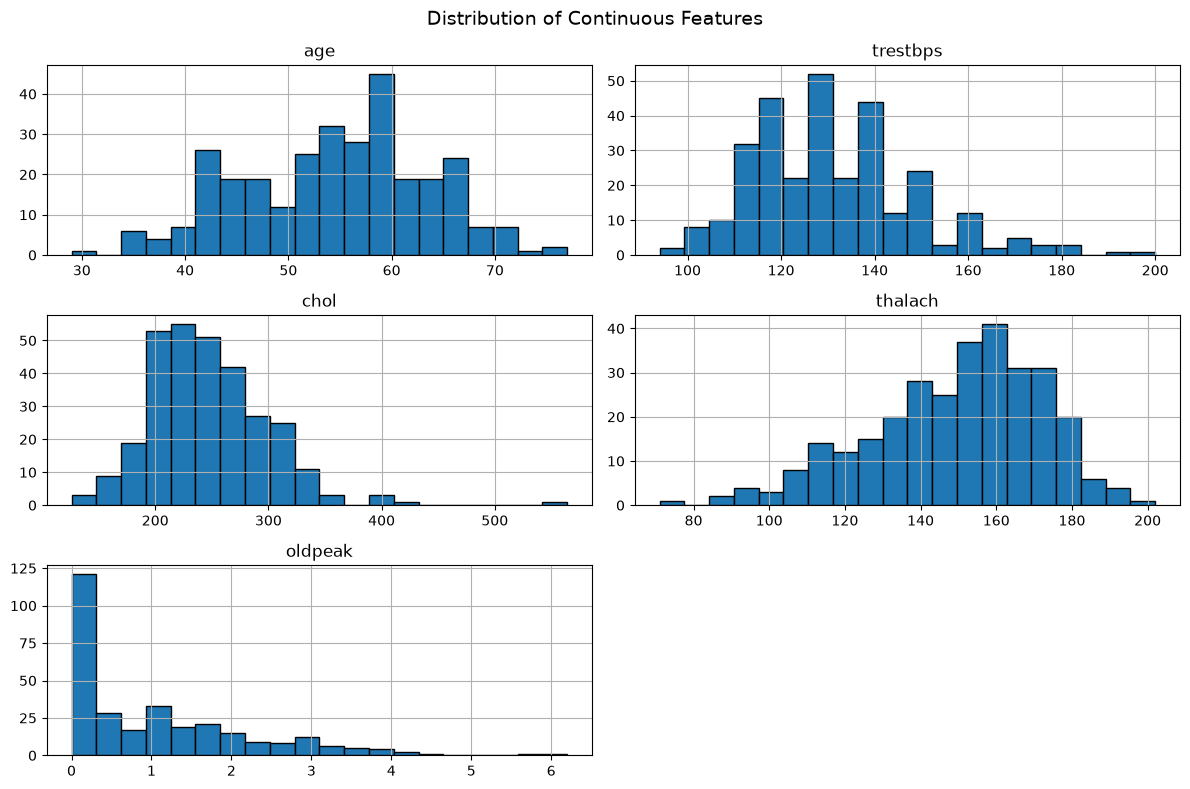

In [8]:
continuous_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
]

df_clean[continuous_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Continuous Features", fontsize=14)
plt.tight_layout()
plt.show()

## 7. Correlation Analysis

A correlation heatmap is used to examine relationships among the numerical variables and the binary target. This can help identify features that have stronger positive or negative associations with heart disease and reveal highly correlated predictors.

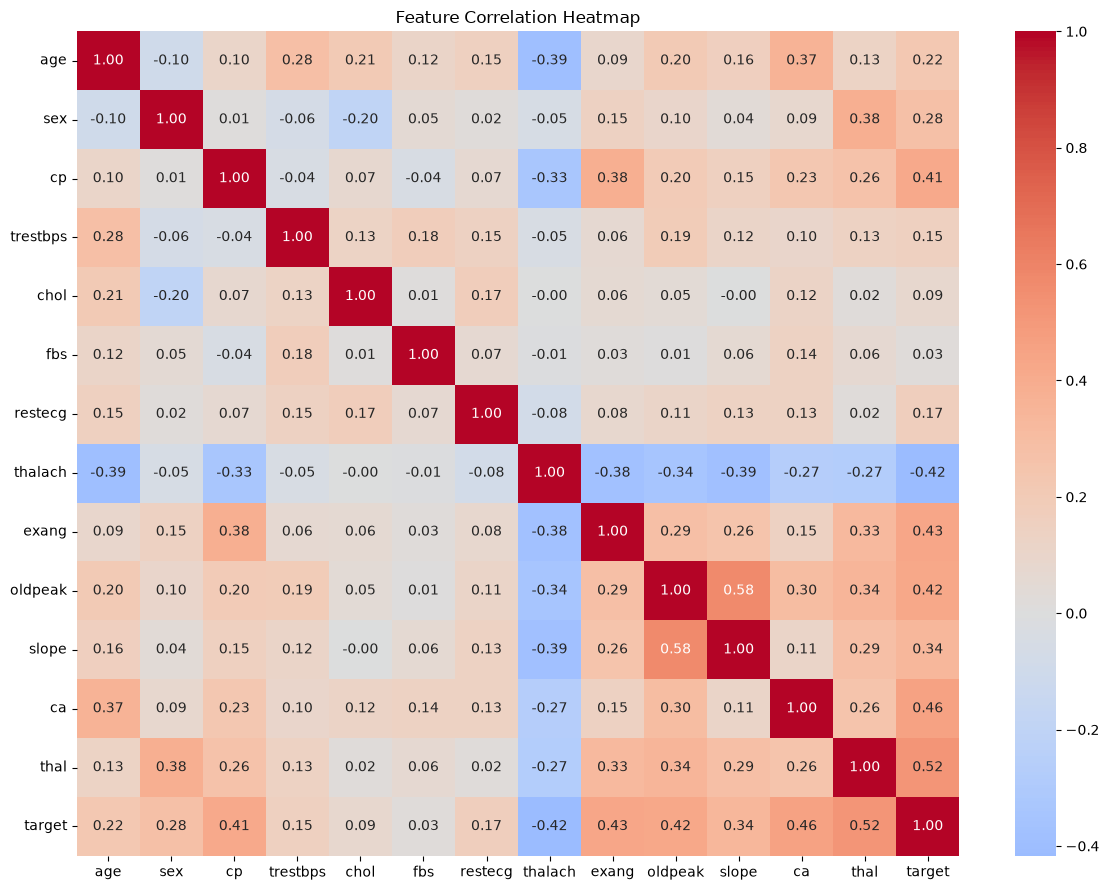

In [9]:
correlation_data = df_clean.drop(columns=["num"])

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. EDA Summary

The exploratory analysis produced the following findings:

- The dataset contains 303 observations and 13 predictor features.
- Missing values are present only in `ca` and `thal`.
- No duplicate observations were identified.
- The original UCI diagnosis variable was converted into a binary target for heart disease prediction.
- The resulting classes are reasonably balanced, with 164 observations in class 0 and 139 observations in class 1.
- Continuous feature distributions were examined using histograms.
- Correlation analysis was performed to examine relationships between the predictors and the binary target.
- Missing values were imputed for exploratory analysis while the original raw dataset remained unchanged.

The preprocessing decisions identified during EDA will be implemented reproducibly in the model development pipeline rather than relying on notebook transformations.

In [10]:
PROCESSED_PATH = Path("../data/processed/heart_disease_clean.csv")

df_clean = df_clean.drop(columns=["num"])

PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(PROCESSED_PATH, index=False)

print(f"Cleaned dataset saved to: {PROCESSED_PATH}")
print(f"Final shape: {df_clean.shape}")

Cleaned dataset saved to: ..\data\processed\heart_disease_clean.csv
Final shape: (303, 14)
